In [14]:
"""
import shutil
import os

# Path to the folder you want to delete
folder_path = '/content/test_data'

# Check if the folder exists before trying to delete it
if os.path.exists(folder_path):
    # Remove the folder and all its contents
    shutil.rmtree(folder_path)
    print(f"Folder '{folder_path}' and all its contents have been deleted successfully.")
else:
    print(f"Folder '{folder_path}' does not exist.")
"""

Folder '/content/test_data' and all its contents have been deleted successfully.


In [15]:
import zipfile
import os

# Path to your zip file (assuming it's in your current Colab directory)
zip_path = '/content/test.zip'

# Directory where you want to extract the contents
extract_to = '/content/test_data'  # You can change this path

# Create the directory if it doesn't exist
os.makedirs(extract_to, exist_ok=True)

# Unzip the file
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to)

print(f"Files extracted to {extract_to}")

Files extracted to /content/test_data


In [13]:
import zipfile
import os

# Path to your zip file (assuming it's in your current Colab directory)
zip_path = '/content/train.zip'

# Directory where you want to extract the contents
extract_to = '/content/train_data'  # You can change this path

# Create the directory if it doesn't exist
os.makedirs(extract_to, exist_ok=True)

# Unzip the file
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to)

print(f"Files extracted to {extract_to}")

Files extracted to /content/train_data


In [23]:
import random
import numpy as np
import keras
from keras import ops
import matplotlib.pyplot as plt
from keras.preprocessing.image import load_img, img_to_array
import os

# Hyperparameters
epochs = 10
batch_size = 16
margin = 1  # Margin for contrastive loss.
img_height, img_width = 224, 224  # Adjust based on your image size

In [29]:
def load_dataset(directory):
    categories = sorted(os.listdir(directory))
    images = []
    labels = []
    class_ids = {category: idx for idx, category in enumerate(categories)}

    print(f"Found {len(categories)} categories: {categories}")

    for category in categories:
        category_path = os.path.join(directory, category)
        img_files = os.listdir(category_path)
        print(f"Loading {len(img_files)} images from {category}")

        for img_name in img_files:
            img_path = os.path.join(category_path, img_name)
            try:
                img = load_img(img_path, target_size=(img_height, img_width), color_mode='rgb')
                img_array = img_to_array(img)
                images.append(img_array)
                labels.append(class_ids[category])
            except Exception as e:
                print(f"Error loading {img_path}: {e}")

    return np.array(images), np.array(labels), class_ids

# Load datasets
train_dir = '/content/train_data/train'
test_dir = '/content/test_data/test'

print("Loading training data...")
x_train, y_train, class_ids = load_dataset(train_dir)
print("\nLoading test data...")
x_test, y_test, _ = load_dataset(test_dir)

# Normalize pixel values
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("\nTraining data shape:", x_train.shape)
print("Test data shape:", x_test.shape)

# Create validation split
val_split = 0.2
num_val = int(len(x_train) * val_split)

x_val = x_train[:num_val]
y_val = y_train[:num_val]
x_train = x_train[num_val:]
y_train = y_train[num_val:]

print("\nAfter split:")
print("Training samples:", len(x_train))
print("Validation samples:", len(x_val))
print("Test samples:", len(x_test))

# Verify class distributions
def print_class_distribution(y, name):
    unique, counts = np.unique(y, return_counts=True)
    print(f"\n{name} class distribution:")
    for cls, count in zip(unique, counts):
        print(f"Class {cls}: {count} samples")

print_class_distribution(y_train, "Training")
print_class_distribution(y_val, "Validation")
print_class_distribution(y_test, "Test")

# Modified make_pairs function
def make_pairs(x, y):
    # Get unique classes present in the data
    unique_classes = np.unique(y)
    num_classes = len(unique_classes)

    # Create indices for each class that exists
    digit_indices = {cls: np.where(y == cls)[0] for cls in unique_classes}

    print("\nClass indices lengths:")
    for cls, indices in digit_indices.items():
        print(f"Class {cls}: {len(indices)} samples")

    pairs = []
    labels = []

    for idx1 in range(len(x)):
        x1 = x[idx1]
        label1 = y[idx1]

        # Matching pair - ensure we can find another sample of same class
        if len(digit_indices[label1]) < 2:
            continue  # skip if only one sample exists for this class

        idx2 = random.choice([i for i in digit_indices[label1] if i != idx1])
        x2 = x[idx2]
        pairs.append([x1, x2])
        labels.append(0)  # 0 = matching pair

        # Non-matching pair - select from different class
        other_classes = [cls for cls in unique_classes if cls != label1 and len(digit_indices[cls]) > 0]
        if not other_classes:
            continue

        label2 = random.choice(other_classes)
        idx2 = random.choice(digit_indices[label2])
        x2 = x[idx2]
        pairs.append([x1, x2])
        labels.append(1)  # 1 = non-matching pair

    return np.array(pairs), np.array(labels).astype("float32")

# Create pairs
print("\nCreating training pairs...")
pairs_train, labels_train = make_pairs(x_train, y_train)

print("\nCreating validation pairs...")
pairs_val, labels_val = make_pairs(x_val, y_val)

print("\nCreating test pairs...")
pairs_test, labels_test = make_pairs(x_test, y_test)

print("\nPair creation complete:")
print(f"Training pairs: {len(pairs_train)}")
print(f"Validation pairs: {len(pairs_val)}")
print(f"Test pairs: {len(pairs_test)}")

Loading training data...
Found 5 categories: ['EOS', 'HAC', 'MMZ', 'MON', 'NGS']
Loading 100 images from EOS
Loading 100 images from HAC
Loading 100 images from MMZ
Loading 100 images from MON
Loading 100 images from NGS

Loading test data...
Found 5 categories: ['EOS', 'HAC', 'MMZ', 'MON', 'NGS']
Loading 59 images from EOS
Loading 82 images from HAC
Loading 2 images from MMZ
Loading 89 images from MON
Loading 10 images from NGS

Training data shape: (500, 224, 224, 3)
Test data shape: (242, 224, 224, 3)

After split:
Training samples: 400
Validation samples: 100
Test samples: 242

Training class distribution:
Class 1: 100 samples
Class 2: 100 samples
Class 3: 100 samples
Class 4: 100 samples

Validation class distribution:
Class 0: 100 samples

Test class distribution:
Class 0: 59 samples
Class 1: 82 samples
Class 2: 2 samples
Class 3: 89 samples
Class 4: 10 samples

Creating training pairs...

Class indices lengths:
Class 1: 100 samples
Class 2: 100 samples
Class 3: 100 samples
Class

Sample training pairs:


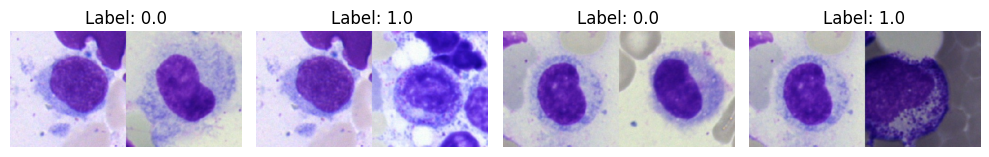

In [30]:
def visualize(pairs, labels, to_show=6, num_col=3, predictions=None, test=False):
    num_row = to_show // num_col if to_show // num_col != 0 else 1
    to_show = num_row * num_col

    fig, axes = plt.subplots(num_row, num_col, figsize=(10, 5))
    for i in range(to_show):
        if num_row == 1:
            ax = axes[i % num_col]
        else:
            ax = axes[i // num_col, i % num_col]

        concatenated = np.concatenate([pairs[i][0], pairs[i][1]], axis=1)
        ax.imshow(concatenated.astype("float32"))
        ax.set_axis_off()
        if test:
            ax.set_title("True: {} | Pred: {:.5f}".format(labels[i], predictions[i][0]))
        else:
            ax.set_title("Label: {}".format(labels[i]))
    plt.tight_layout()
    plt.show()

print("Sample training pairs:")
visualize(pairs_train[:-1], labels_train[:-1], to_show=4, num_col=4)

In [31]:
def euclidean_distance(vects):
    x, y = vects
    sum_square = ops.sum(ops.square(x - y), axis=1, keepdims=True)
    return ops.sqrt(ops.maximum(sum_square, keras.backend.epsilon()))

# Embedding network
input = keras.layers.Input((img_height, img_width, 3))
x = keras.layers.BatchNormalization()(input)
x = keras.layers.Conv2D(32, (3, 3), activation="relu")(x)
x = keras.layers.MaxPooling2D(pool_size=(2, 2))(x)
x = keras.layers.Conv2D(64, (3, 3), activation="relu")(x)
x = keras.layers.MaxPooling2D(pool_size=(2, 2))(x)
x = keras.layers.Flatten()(x)
x = keras.layers.BatchNormalization()(x)
x = keras.layers.Dense(128, activation="relu")(x)
embedding_network = keras.Model(input, x)

# Siamese network
input_1 = keras.layers.Input((img_height, img_width, 3))
input_2 = keras.layers.Input((img_height, img_width, 3))

tower_1 = embedding_network(input_1)
tower_2 = embedding_network(input_2)

merge_layer = keras.layers.Lambda(euclidean_distance)([tower_1, tower_2])
normal_layer = keras.layers.BatchNormalization()(merge_layer)
output_layer = keras.layers.Dense(1, activation="sigmoid")(normal_layer)
siamese = keras.Model(inputs=[input_1, input_2], outputs=output_layer)

siamese.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ functional          │ (None, 128)       │ 24,653,900 │ input_layer_1[0]… │
│ (Functional)        │                   │            │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda (Lambda)     │ (None, 1)         │          0 │ functional[0][0], │
│                     │                   │            │ functional[1][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 1)         │          4 │ lambda[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1)         │          2 │ batch_normalizat… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 24,653,906 (94.05 MB)

 Trainable params: 24,280,650 (92.62 MB)

 Non-trainable params: 373,256 (1.42 MB)

In [32]:
def loss(margin=1):
    def contrastive_loss(y_true, y_pred):
        square_pred = ops.square(y_pred)
        margin_square = ops.square(ops.maximum(margin - (y_pred), 0))
        return ops.mean((1 - y_true) * square_pred + (y_true) * margin_square)
    return contrastive_loss

siamese.compile(loss=loss(margin=margin), optimizer="adam", metrics=["accuracy"])

history = siamese.fit(
    [pairs_train[:, 0], pairs_train[:, 1]],
    labels_train,
    validation_data=([pairs_val[:, 0], pairs_val[:, 1]], labels_val),
    batch_size=batch_size,
    epochs=epochs,
)

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 182s 3s/step - accuracy: 0.5450 - loss: 0.2831 - val_accuracy: 0.9900 - val_loss: 0.0964
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 192s 3s/step - accuracy: 0.5741 - loss: 0.2751 - val_accuracy: 0.8900 - val_loss: 0.1448
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 197s 3s/step - accuracy: 0.5959 - loss: 0.2549 - val_accuracy: 0.7400 - val_loss: 0.1748
Epoch 4/10
44/50 ━━━━━━━━━━━━━━━━━━━━ 19s 3s/step - accuracy: 0.6335 - loss: 0.2306

KeyboardInterrupt: 

In [ ]:
def plt_metric(history, metric, title, has_valid=True):
    plt.plot(history.history[metric])
    if has_valid:
        plt.plot(history.history["val_" + metric])
        plt.legend(["train", "validation"], loc="upper left")
    plt.title(title)
    plt.ylabel(metric)
    plt.xlabel("epoch")
    plt.show()

plt_metric(history, "accuracy", "Model accuracy")
plt_metric(history, "loss", "Contrastive Loss")

results = siamese.evaluate([pairs_test[:, 0], pairs_test[:, 1]], labels_test)
print("Test loss, test accuracy:", results)

predictions = siamese.predict([pairs_test[:, 0], pairs_test[:, 1]])
visualize(pairs_test, labels_test, to_show=3, predictions=predictions, test=True)

embedding_network.save('siamese_embedding.h5')
siamese.save('siamese_model.h5')